# RaphIA · Clasificador de enfermedades: EfficientNet-B2 frente a otros modelos

**Qué hace este notebook:**
1. Entrena **EfficientNet-B2** (el modelo del sistema) y, con la misma receta, **EfficientNet-B0, ResNet-50 y MobileNetV3**.
2. Todos usan la **misma versión del dataset**, así la comparación es justa.
3. Cada red se entrena con su tamaño nativo: B2 a 288×288 y las demás a 224×224.
4. Compara todos con las mismas imágenes de prueba y exporta todos a ONNX para la prueba de campo (notebook 03).

**Antes de empezar:** `Entorno de ejecución → Cambiar tipo de entorno → GPU`.

### 1. Instalación de librerías

In [1]:
!pip install -q roboflow onnx onnxscript onnxruntime scikit-learn

### 2. Verificación de la GPU

In [2]:
import torch
print("Torch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))
DEVICE = torch.device("cuda")

Torch: 2.14.1+cu130
GPU: NVIDIA A100-SXM4-40GB


### 3. Montar Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 4. Carpeta de resultados
Todo lo que genera este notebook se guarda aquí (no se pierde al cerrar Colab).

In [4]:
import os

RAIZ = "/content/drive/MyDrive/Paper VISAPP 2027 (Modelos)"
CARPETA_RESULTADOS = f"{RAIZ}/Modelos/Resultados/02_Clasificadores"

os.makedirs(CARPETA_RESULTADOS, exist_ok=True)
print("Resultados en:", CARPETA_RESULTADOS)

Resultados en: /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/02_Clasificadores


### 5. Descarga del dataset (Roboflow)
Pon el número de la versión exportada a **288×288**. Al cambiar el tamaño en Roboflow se crea una versión nueva (por ejemplo, la 17).

In [5]:
from roboflow import Roboflow

##VERSION_DATASET = 17   # <- la versión exportada a 288x288



rf = Roboflow(api_key="v9FkUYCoBtYr4mjWeNfw")
project = rf.workspace("upc-cqrba").project("leaf-clasification-bpv9q")
version = project.version(17)
dataset = version.download("folder", location="/content/dataset_clasificacion")


TRAIN_DIR = "/content/dataset_clasificacion/train"
VAL_DIR = "/content/dataset_clasificacion/valid"
TEST_DIR = "/content/dataset_clasificacion/test"

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/dataset_clasificacion in folder:: 100%|██████████| 8673/8673 [00:00<00:00, 10321.70it/s]


### 6. Revisar el tamaño de las imágenes descargadas
Debe decir (288, 288).

In [6]:
from PIL import Image
primera_clase = sorted(os.listdir(TRAIN_DIR))[0]
primera_imagen = sorted(os.listdir(f"{TRAIN_DIR}/{primera_clase}"))[0]
Image.open(f"{TRAIN_DIR}/{primera_clase}/{primera_imagen}").size

(288, 288)

### 7. Conteo de imágenes por clase y partición
`train` ya incluye las copias aumentadas por Roboflow (×3).

In [7]:
import pandas as pd

def contar(carpeta):
    return {clase: len(os.listdir(f"{carpeta}/{clase}")) for clase in sorted(os.listdir(carpeta))}

conteo = pd.DataFrame({"train": contar(TRAIN_DIR), "valid": contar(VAL_DIR), "test": contar(TEST_DIR)})
conteo.loc["Total"] = conteo.sum()
conteo.to_csv(f"{CARPETA_RESULTADOS}/conteo_dataset.csv")
conteo

,train,valid,test
Early Blight,2274,190,201
Healthy,2295,136,137
Late Blight,3018,216,204
Total,7587,542,542


### 8. Configuración del entrenamiento (la misma de tu EfficientNet-B2)

In [ ]:
EPOCAS = 50
BATCH = 50
LR = 0.001
SEMILLA = 0
CLASES = ["Early Blight", "Healthy", "Late Blight"]

torch.manual_seed(SEMILLA)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

### 9. Transformaciones y carga de imágenes
Iguales a tu notebook de EfficientNet: volteos, rotación de 15° y brillo/contraste solo en entrenamiento.

In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

MEDIA, DESV = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def crear_loaders(tamano):
    t_train = transforms.Compose([
        transforms.Resize((tamano, tamano)),
        transforms.RandomHorizontalFlip(0.5),
        transforms.RandomVerticalFlip(0.5),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.1, contrast=0.1),
        transforms.ToTensor(),
        transforms.Normalize(MEDIA, DESV),
    ])
    t_eval = transforms.Compose([transforms.Resize((tamano, tamano)), transforms.ToTensor(), transforms.Normalize(MEDIA, DESV)])
    train = DataLoader(datasets.ImageFolder(TRAIN_DIR, t_train), batch_size=BATCH, shuffle=True, num_workers=2)
    val = DataLoader(datasets.ImageFolder(VAL_DIR, t_eval), batch_size=BATCH, num_workers=2)
    test = DataLoader(datasets.ImageFolder(TEST_DIR, t_eval), batch_size=BATCH, num_workers=2)
    return train, val, test

### 10. Crear un modelo preentrenado en ImageNet con 3 clases

In [ ]:
import torch.nn as nn
from torchvision import models

def crear_modelo(nombre):
    if nombre == "efficientnet_b2":
        m = models.efficientnet_b2(weights="DEFAULT")
        m.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(m.classifier[1].in_features, 3))
    elif nombre == "efficientnet_b0":
        m = models.efficientnet_b0(weights="DEFAULT")
        m.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(m.classifier[1].in_features, 3))
    elif nombre == "resnet50":
        m = models.resnet50(weights="DEFAULT")
        m.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(m.fc.in_features, 3))
    elif nombre == "mobilenet_v3_large":
        m = models.mobilenet_v3_large(weights="DEFAULT")
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, 3)
    return m.to(DEVICE)

### 11. Función de entrenamiento
Igual que tu notebook: Adam, *scheduler* que baja la tasa de aprendizaje a la mitad tras 3 épocas sin mejorar y se guarda el modelo con **menor pérdida de validación** (sin *early stopping*). El mejor modelo y el historial se guardan en Drive.

In [ ]:
import torch.optim as optim

def entrenar(nombre, tamano):
    train, val, _ = crear_loaders(tamano)
    modelo = crear_modelo(nombre)
    criterio = nn.CrossEntropyLoss()
    optimizador = optim.Adam(modelo.parameters(), lr=LR)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="min", factor=0.5, patience=3)
    historial, mejor = [], float("inf")

    for epoca in range(1, EPOCAS + 1):
        modelo.train(); perdida_train = 0
        for x, y in train:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizador.zero_grad(); perdida = criterio(modelo(x), y); perdida.backward(); optimizador.step()
            perdida_train += perdida.item() * x.size(0)

        modelo.eval(); perdida_val = 0; aciertos = 0
        with torch.no_grad():
            for x, y in val:
                x, y = x.to(DEVICE), y.to(DEVICE); salida = modelo(x)
                perdida_val += criterio(salida, y).item() * x.size(0); aciertos += (salida.argmax(1) == y).sum().item()

        perdida_train /= len(train.dataset); perdida_val /= len(val.dataset); acc_val = aciertos / len(val.dataset)
        scheduler.step(perdida_val)
        historial.append({"epoca": epoca, "perdida_train": perdida_train, "perdida_val": perdida_val, "acc_val": acc_val})
        marca = ""
        if perdida_val < mejor:
            mejor = perdida_val; torch.save(modelo.state_dict(), f"{CARPETA_RESULTADOS}/{nombre}_best.pth"); marca = "  <- mejor modelo"
        print(f"Época {epoca:02d} | pérdida train {perdida_train:.4f} | pérdida val {perdida_val:.4f} | acc val {acc_val*100:.2f}%{marca}")

    pd.DataFrame(historial).to_csv(f"{CARPETA_RESULTADOS}/{nombre}_historial.csv", index=False)

### 12. Entrenamiento EfficientNet-B2 (288×288), el modelo del sistema

In [ ]:
entrenar("efficientnet_b2", 288)

Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 209MB/s]


Época 01 | pérdida train 0.1119 | pérdida val 0.0524 | acc val 98.89%  <- mejor modelo
Época 02 | pérdida train 0.0436 | pérdida val 0.0159 | acc val 99.63%  <- mejor modelo
Época 03 | pérdida train 0.0310 | pérdida val 0.0271 | acc val 99.26%
Época 04 | pérdida train 0.0311 | pérdida val 0.0428 | acc val 98.89%
Época 05 | pérdida train 0.0244 | pérdida val 0.0347 | acc val 99.08%
Época 06 | pérdida train 0.0093 | pérdida val 0.0658 | acc val 99.08%
Época 07 | pérdida train 0.0106 | pérdida val 0.0463 | acc val 99.45%
Época 08 | pérdida train 0.0050 | pérdida val 0.0578 | acc val 99.45%
Época 09 | pérdida train 0.0017 | pérdida val 0.0649 | acc val 99.45%
Época 10 | pérdida train 0.0046 | pérdida val 0.0517 | acc val 98.89%
Época 11 | pérdida train 0.0019 | pérdida val 0.0547 | acc val 99.45%
Época 12 | pérdida train 0.0007 | pérdida val 0.0538 | acc val 99.45%
Época 13 | pérdida train 0.0012 | pérdida val 0.0627 | acc val 99.45%
Época 14 | pérdida train 0.0009 | pérdida val 0.0531 | a

### 13. Entrenamiento EfficientNet-B0 (224×224)

In [ ]:
entrenar("efficientnet_b0", 224)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 201MB/s]


Época 01 | pérdida train 0.1221 | pérdida val 0.0313 | acc val 99.26%  <- mejor modelo
Época 02 | pérdida train 0.0524 | pérdida val 0.0373 | acc val 99.08%
Época 03 | pérdida train 0.0310 | pérdida val 0.0265 | acc val 99.63%  <- mejor modelo
Época 04 | pérdida train 0.0225 | pérdida val 0.0601 | acc val 99.08%
Época 05 | pérdida train 0.0253 | pérdida val 0.0237 | acc val 99.45%  <- mejor modelo
Época 06 | pérdida train 0.0320 | pérdida val 0.0239 | acc val 99.08%
Época 07 | pérdida train 0.0210 | pérdida val 0.0660 | acc val 99.08%
Época 08 | pérdida train 0.0181 | pérdida val 0.0290 | acc val 99.26%
Época 09 | pérdida train 0.0082 | pérdida val 0.0536 | acc val 99.26%
Época 10 | pérdida train 0.0039 | pérdida val 0.0666 | acc val 99.26%
Época 11 | pérdida train 0.0055 | pérdida val 0.0456 | acc val 99.45%
Época 12 | pérdida train 0.0017 | pérdida val 0.0371 | acc val 99.45%
Época 13 | pérdida train 0.0044 | pérdida val 0.0413 | acc val 99.26%
Época 14 | pérdida train 0.0020 | pérdi

### 14. Entrenamiento ResNet-50 (224×224)

In [ ]:
entrenar("resnet50", 224)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 235MB/s]


Época 01 | pérdida train 0.1825 | pérdida val 0.0860 | acc val 97.23%  <- mejor modelo
Época 02 | pérdida train 0.0851 | pérdida val 0.0478 | acc val 98.71%  <- mejor modelo
Época 03 | pérdida train 0.0693 | pérdida val 0.0163 | acc val 99.08%  <- mejor modelo
Época 04 | pérdida train 0.0484 | pérdida val 0.0482 | acc val 99.26%
Época 05 | pérdida train 0.0520 | pérdida val 0.0345 | acc val 99.08%
Época 06 | pérdida train 0.0488 | pérdida val 0.0348 | acc val 98.71%
Época 07 | pérdida train 0.0401 | pérdida val 0.0404 | acc val 98.89%
Época 08 | pérdida train 0.0231 | pérdida val 0.0358 | acc val 99.26%
Época 09 | pérdida train 0.0130 | pérdida val 0.0393 | acc val 98.71%
Época 10 | pérdida train 0.0117 | pérdida val 0.0233 | acc val 99.45%
Época 11 | pérdida train 0.0104 | pérdida val 0.0439 | acc val 99.26%
Época 12 | pérdida train 0.0063 | pérdida val 0.0248 | acc val 99.26%
Época 13 | pérdida train 0.0026 | pérdida val 0.0219 | acc val 99.26%
Época 14 | pérdida train 0.0027 | pérdi

### 15. Entrenamiento MobileNetV3-Large (224×224)

In [ ]:
entrenar("mobilenet_v3_large", 224)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 199MB/s]


Época 01 | pérdida train 0.1083 | pérdida val 0.0808 | acc val 98.71%  <- mejor modelo
Época 02 | pérdida train 0.0418 | pérdida val 0.0753 | acc val 98.52%  <- mejor modelo
Época 03 | pérdida train 0.0318 | pérdida val 0.0742 | acc val 98.71%  <- mejor modelo
Época 04 | pérdida train 0.0238 | pérdida val 0.1124 | acc val 98.52%
Época 05 | pérdida train 0.0197 | pérdida val 0.1469 | acc val 98.71%
Época 06 | pérdida train 0.0232 | pérdida val 0.0527 | acc val 99.26%  <- mejor modelo
Época 07 | pérdida train 0.0255 | pérdida val 0.0459 | acc val 97.97%  <- mejor modelo
Época 08 | pérdida train 0.0108 | pérdida val 0.0355 | acc val 98.89%  <- mejor modelo
Época 09 | pérdida train 0.0148 | pérdida val 0.0208 | acc val 98.89%  <- mejor modelo
Época 10 | pérdida train 0.0138 | pérdida val 0.0486 | acc val 99.08%
Época 11 | pérdida train 0.0125 | pérdida val 1.1411 | acc val 89.85%
Época 12 | pérdida train 0.0162 | pérdida val 0.1097 | acc val 98.34%
Época 13 | pérdida train 0.0156 | pérdida

### 16. Evaluación en el conjunto de prueba
Carga el mejor modelo desde Drive, así funciona aunque la sesión se haya reiniciado.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

def evaluar_pytorch(nombre, tamano):
    _, _, test = crear_loaders(tamano)
    modelo = crear_modelo(nombre)
    modelo.load_state_dict(torch.load(f"{CARPETA_RESULTADOS}/{nombre}_best.pth", map_location=DEVICE))
    modelo.eval(); reales, predichos = [], []
    with torch.no_grad():
        for x, y in test:
            predichos += modelo(x.to(DEVICE)).argmax(1).cpu().tolist(); reales += y.tolist()
    print(classification_report(reales, predichos, target_names=CLASES, digits=4))
    print("Matriz (filas = real, columnas = predicho):")
    print(confusion_matrix(reales, predichos))
    return {"modelo": nombre, "entrada": tamano, "parametros_M": round(sum(p.numel() for p in modelo.parameters()) / 1e6, 2),
            "accuracy": round(accuracy_score(reales, predichos), 4), "macro_F1": round(f1_score(reales, predichos, average="macro"), 4),
            "matriz": confusion_matrix(reales, predichos).tolist()}

In [ ]:
res_b2 = evaluar_pytorch("efficientnet_b2", 288)

              precision    recall  f1-score   support

Early Blight     1.0000    0.9950    0.9975       201
     Healthy     1.0000    1.0000    1.0000       137
 Late Blight     0.9951    1.0000    0.9976       204

    accuracy                         0.9982       542
   macro avg     0.9984    0.9983    0.9984       542
weighted avg     0.9982    0.9982    0.9982       542

Matriz (filas = real, columnas = predicho):
[[200   0   1]
 [  0 137   0]
 [  0   0 204]]


In [ ]:
res_b0 = evaluar_pytorch("efficientnet_b0", 224)

              precision    recall  f1-score   support

Early Blight     0.9901    0.9950    0.9926       201
     Healthy     0.9928    1.0000    0.9964       137
 Late Blight     1.0000    0.9902    0.9951       204

    accuracy                         0.9945       542
   macro avg     0.9943    0.9951    0.9947       542
weighted avg     0.9945    0.9945    0.9945       542

Matriz (filas = real, columnas = predicho):
[[200   1   0]
 [  0 137   0]
 [  2   0 202]]


In [ ]:
res_resnet = evaluar_pytorch("resnet50", 224)

              precision    recall  f1-score   support

Early Blight     0.9950    0.9851    0.9900       201
     Healthy     0.9927    0.9927    0.9927       137
 Late Blight     0.9854    0.9951    0.9902       204

    accuracy                         0.9908       542
   macro avg     0.9910    0.9910    0.9910       542
weighted avg     0.9908    0.9908    0.9908       542

Matriz (filas = real, columnas = predicho):
[[198   1   2]
 [  0 136   1]
 [  1   0 203]]


In [ ]:
res_mobilenet = evaluar_pytorch("mobilenet_v3_large", 224)

              precision    recall  f1-score   support

Early Blight     0.9950    0.9900    0.9925       201
     Healthy     0.9927    0.9927    0.9927       137
 Late Blight     0.9902    0.9951    0.9927       204

    accuracy                         0.9926       542
   macro avg     0.9926    0.9926    0.9926       542
weighted avg     0.9926    0.9926    0.9926       542

Matriz (filas = real, columnas = predicho):
[[199   1   1]
 [  0 136   1]
 [  1   0 203]]


### 17. Tabla comparativa en el conjunto de prueba

In [ ]:
tabla = pd.DataFrame([res_b2, res_b0, res_resnet, res_mobilenet]).drop(columns="matriz")
tabla.to_csv(f"{CARPETA_RESULTADOS}/comparacion_clasificadores.csv", index=False)
tabla

,modelo,entrada,parametros_M,accuracy,macro_F1
0,efficientnet_b2,288,7.71,0.9982,0.9984
1,efficientnet_b0,224,4.01,0.9945,0.9947
2,resnet50,224,23.51,0.9908,0.9910
3,mobilenet_v3_large,224,4.21,0.9926,0.9926


### 18. Figura: matriz de confusión de EfficientNet-B2

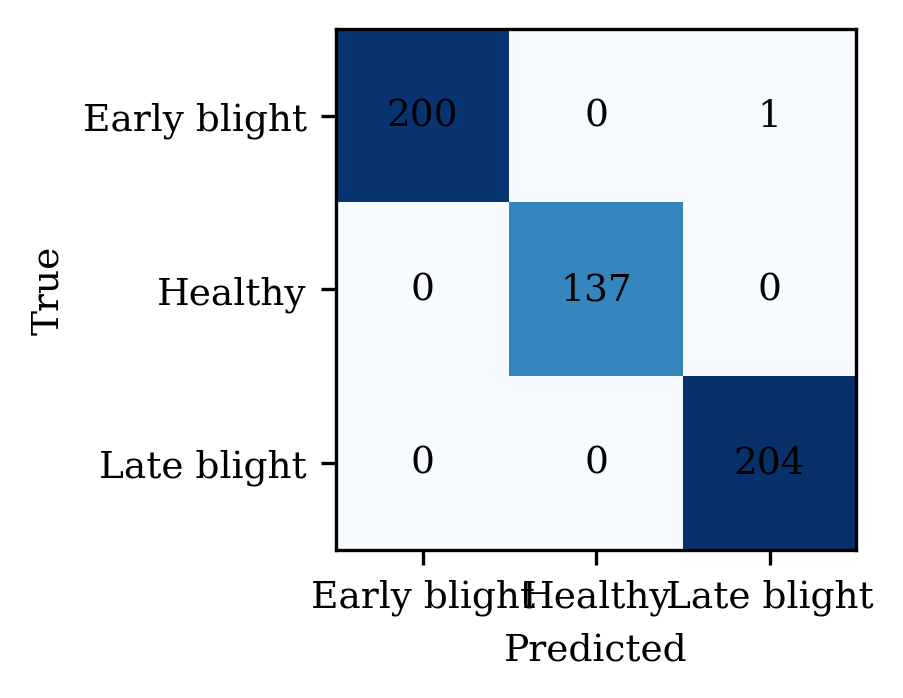

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "serif", "font.size": 9})

matriz = np.array(res_b2["matriz"])
etiquetas = ["Early blight", "Healthy", "Late blight"]
fig, ax = plt.subplots(figsize=(3.0, 2.4), dpi=300)
ax.imshow(matriz, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, matriz[i, j], ha="center", va="center")
ax.set_xticks(range(3)); ax.set_xticklabels(etiquetas)
ax.set_yticks(range(3)); ax.set_yticklabels(etiquetas)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
fig.tight_layout()
fig.savefig(f"{CARPETA_RESULTADOS}/fig_b2_confusion_matrix.png", bbox_inches="tight")
plt.show()

### 19. Figura: curvas de pérdida (una por modelo)

In [ ]:
def graficar_curva(nombre, titulo):
    h = pd.read_csv(f"{CARPETA_RESULTADOS}/{nombre}_historial.csv")
    fig, ax = plt.subplots(figsize=(3.3, 2.4), dpi=300)
    ax.plot(h["epoca"], h["perdida_train"], label="Train")
    ax.plot(h["epoca"], h["perdida_val"], label="Validation")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy loss"); ax.set_title(titulo); ax.legend()
    fig.tight_layout()
    fig.savefig(f"{CARPETA_RESULTADOS}/fig_{nombre}_loss.png", bbox_inches="tight")
    plt.show()

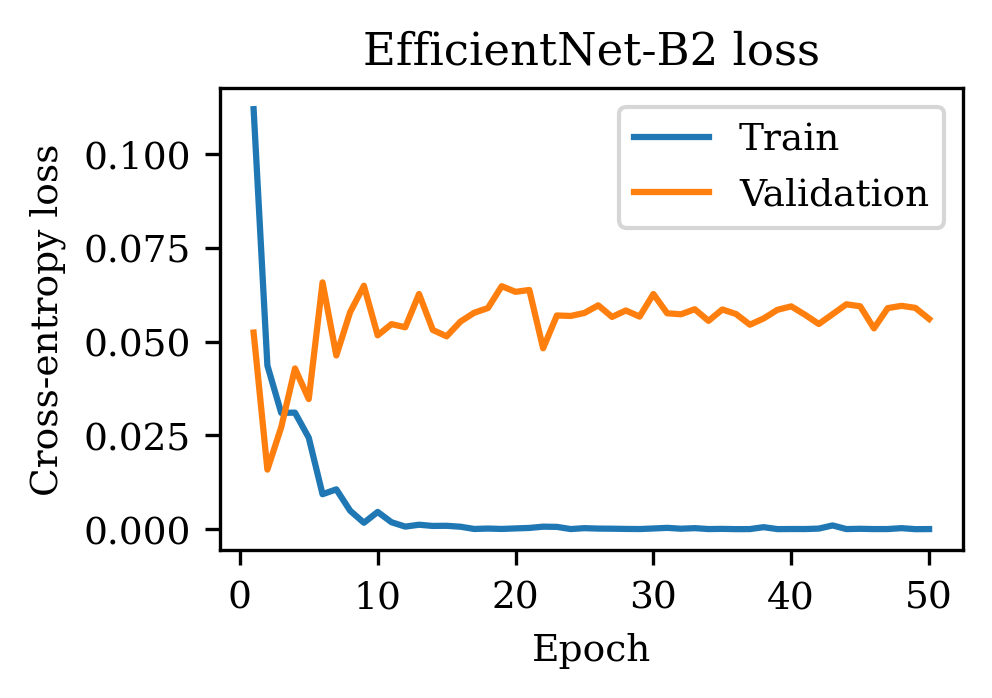

In [ ]:
graficar_curva("efficientnet_b2", "EfficientNet-B2 loss")

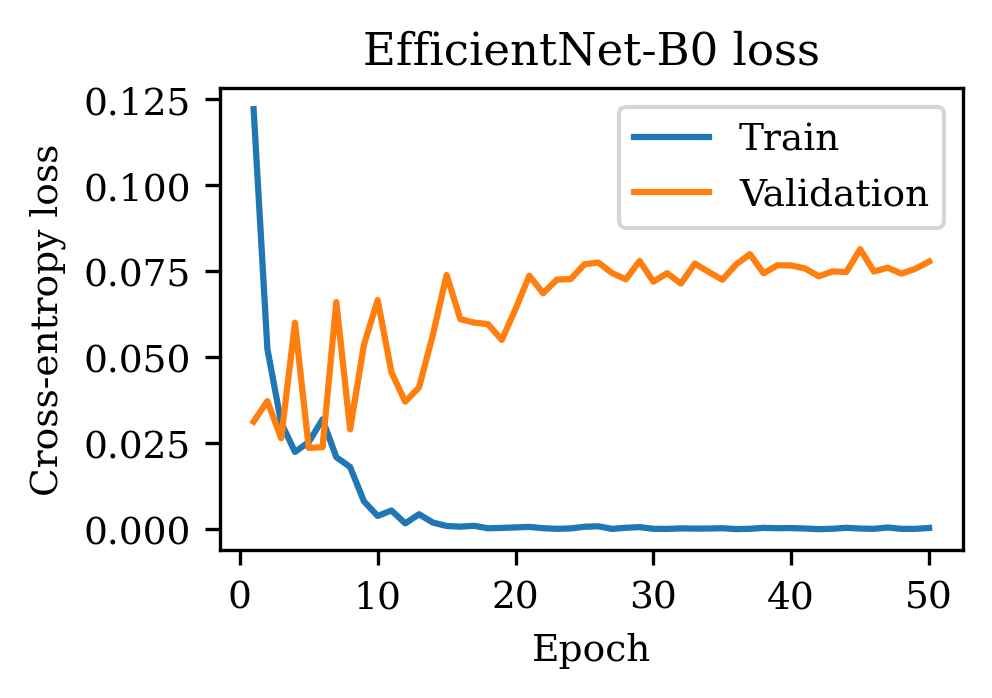

In [ ]:
graficar_curva("efficientnet_b0", "EfficientNet-B0 loss")

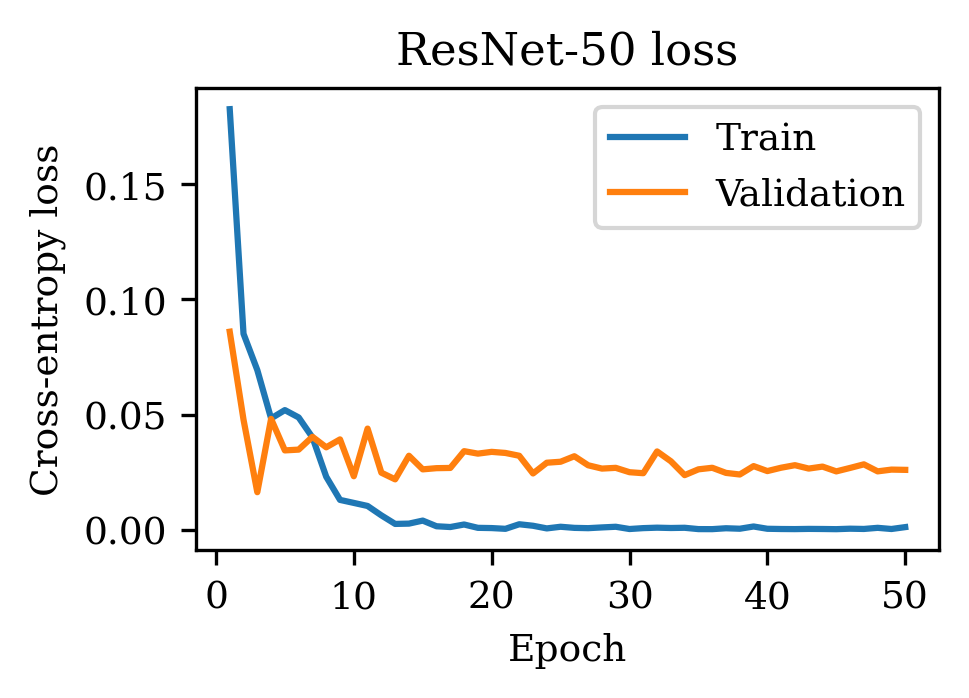

In [ ]:
graficar_curva("resnet50", "ResNet-50 loss")

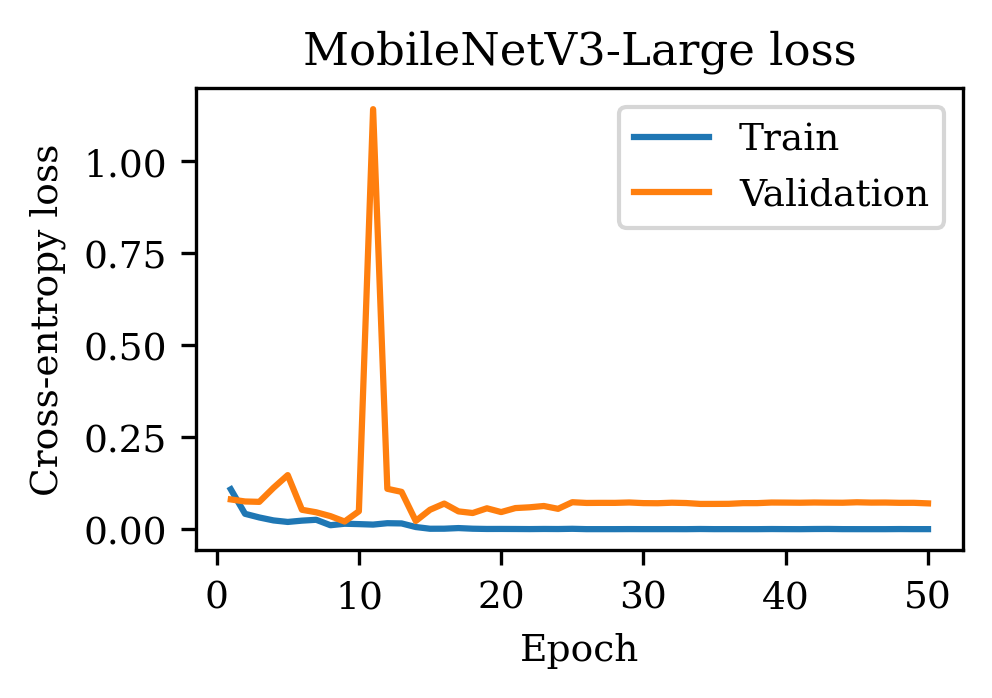

In [ ]:
graficar_curva("mobilenet_v3_large", "MobileNetV3-Large loss")

### 20. Exportar a ONNX (para la prueba de campo y Cloud Run)
Mismo formato que tu `EfficientNet-B2_RAPHIA.onnx`: entrada RGB de 0 a 255, la normalización va dentro del modelo, FP32 y opset 18.
`efficientnet_b2.onnx` es el que irá a Cloud Run.

In [ ]:
import onnx

class ConNormalizacion(nn.Module):
    def __init__(self, modelo):
        super().__init__()
        self.modelo = modelo
        self.register_buffer("media", torch.tensor(MEDIA).view(1, 3, 1, 1))
        self.register_buffer("desv", torch.tensor(DESV).view(1, 3, 1, 1))
    def forward(self, x):
        return self.modelo((x / 255.0 - self.media) / self.desv)

def exportar_onnx(nombre, tamano):
    modelo = crear_modelo(nombre).cpu()
    modelo.load_state_dict(torch.load(f"{CARPETA_RESULTADOS}/{nombre}_best.pth", map_location="cpu"))
    envuelto = ConNormalizacion(modelo).eval()
    temporal, final = f"/content/{nombre}_tmp.onnx", f"{CARPETA_RESULTADOS}/{nombre}.onnx"
    torch.onnx.export(envuelto, torch.rand(1, 3, tamano, tamano) * 255, temporal, opset_version=18,
                      input_names=["input"], output_names=["output"])
    onnx.save_model(onnx.load(temporal), final, save_as_external_data=False)
    print("Guardado:", final)

In [ ]:
exportar_onnx("efficientnet_b2", 288)

[torch.onnx] Obtain model graph for `ConNormalizacion([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ConNormalizacion([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Guardado: /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/02_Clasificadores/efficientnet_b2.onnx


In [ ]:
exportar_onnx("efficientnet_b0", 224)

[torch.onnx] Obtain model graph for `ConNormalizacion([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ConNormalizacion([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Guardado: /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/02_Clasificadores/efficientnet_b0.onnx


In [ ]:
exportar_onnx("resnet50", 224)

[torch.onnx] Obtain model graph for `ConNormalizacion([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ConNormalizacion([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Guardado: /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/02_Clasificadores/resnet50.onnx


In [ ]:
exportar_onnx("mobilenet_v3_large", 224)

[torch.onnx] Obtain model graph for `ConNormalizacion([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ConNormalizacion([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Guardado: /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/02_Clasificadores/mobilenet_v3_large.onnx


### 21. Guardar el resumen
Pásame `resumen_clasificadores.json`, `comparacion_clasificadores.csv` y `conteo_dataset.csv`.

In [ ]:
VERSION_DATASET= 17

In [ ]:
import json

resumen = {
    "gpu": torch.cuda.get_device_name(0),
    "configuracion": {"epocas": EPOCAS, "batch": BATCH, "lr": LR, "optimizador": "Adam",
                      "scheduler": "ReduceLROnPlateau(factor=0.5, patience=3)", "mejor_modelo": "menor perdida de validacion",
                      "early_stopping": False, "semilla": SEMILLA},
    "onnx": {"opset": 18, "precision": "FP32", "cuantizacion": "ninguna"},
    "version_dataset": VERSION_DATASET,
    "tamanos_entrada": {"efficientnet_b2": 288, "efficientnet_b0": 224, "resnet50": 224, "mobilenet_v3_large": 224},
    "conteo_dataset": conteo.to_dict(),
    "resultados": [res_b2, res_b0, res_resnet, res_mobilenet],
}
json.dump(resumen, open(f"{CARPETA_RESULTADOS}/resumen_clasificadores.json", "w"), indent=2, default=float)
print("Guardado en", CARPETA_RESULTADOS)

Guardado en /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/02_Clasificadores


### Evaluacion del modelo original vs el onnx

In [8]:
import onnxruntime as ort
import numpy as np
from PIL import Image

In [9]:
def evaluar_onnx(nombre, tamano):
    sesion = ort.InferenceSession(f"{CARPETA_RESULTADOS}/{nombre}.onnx", providers=["CPUExecutionProvider"])
    entrada = sesion.get_inputs()[0].name
    reales, predichos = [], []
    for k, clase in enumerate(sorted(os.listdir(TEST_DIR))):
        for archivo in sorted(os.listdir(f"{TEST_DIR}/{clase}")):
            imagen = Image.open(f"{TEST_DIR}/{clase}/{archivo}").convert("RGB").resize((tamano, tamano))
            x = np.asarray(imagen, dtype=np.float32).transpose(2, 0, 1)[None]   # RGB 0-255, como en el sistema
            predichos.append(int(sesion.run(None, {entrada: x})[0].argmax()))
            reales.append(k)
    return np.array(reales), np.array(predichos)

In [10]:
reales, pred_onnx = evaluar_onnx("efficientnet_b2", 288)
print("Accuracy ONNX:", round(100 * (reales == pred_onnx).mean(), 2), "%")
print("Aciertos:", (reales == pred_onnx).sum(), "de", len(reales))

Accuracy ONNX: 99.82 %
Aciertos: 541 de 542


In [11]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(reales, pred_onnx))R

[[200   0   1]
 [  0 137   0]
 [  0   0 204]]
